In [2]:
#load and prepare
import os
import pandas as pd
import matplotlib.pyplot as plt

C = "../data/clean/"
OUT = "../outputs/"
os.makedirs(OUT, exist_ok=True)

students = pd.read_csv(C + "students_clean.csv", parse_dates=["signup_date"])
quiz = pd.read_csv(C + "quiz_clean.csv", parse_dates=["attempted_at"])
outcome = pd.read_csv(C + "outcome_clean.csv")
END = pd.Timestamp("2026-09-30 23:59:59")   # course end date

In [3]:
#one row per student, just what we need for plotting
g = quiz.groupby("student_id")
agg = pd.DataFrame({
    "n_attempts": g.size(),
    "mean_score": g.score.mean(),
    "last_attempt": g.attempted_at.max(),
})
eda = (students.merge(outcome[["student_id", "dropped"]], on="student_id")
               .merge(agg, on="student_id", how="left"))
eda["n_attempts"] = eda.n_attempts.fillna(0)
eda["days_since_last"] = (END - eda.last_attempt).dt.days
print(eda.shape, "dropout rate:", eda.dropped.mean())

(500, 11) dropout rate: 0.25


                  mean  size
attempt_band                
0-2           0.714286    63
3-4           0.394558   147
5-6           0.119565   184
7+            0.000000   106


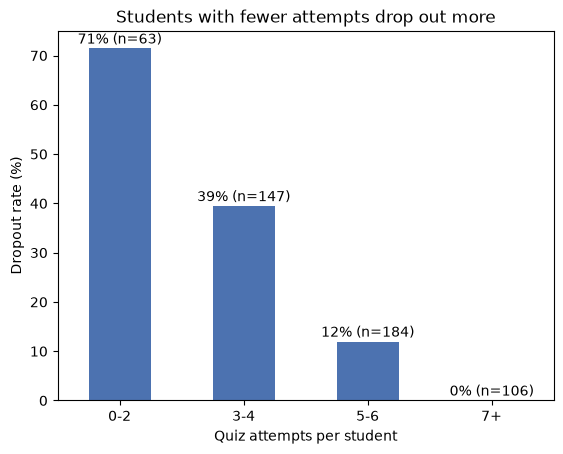

In [4]:
#Finding 1, dropout vs number of attempts
eda["attempt_band"] = pd.cut(eda.n_attempts, [-1, 2, 4, 6, 99], labels=["0-2", "3-4", "5-6", "7+"])
f1 = eda.groupby("attempt_band", observed=True).dropped.agg(["mean", "size"])
print(f1)

ax = (f1["mean"] * 100).plot(kind="bar", color="#4c72b0", rot=0)
for i, (m, n) in enumerate(zip(f1["mean"], f1["size"])):
    ax.text(i, m * 100 + 1, f"{m*100:.0f}% (n={n})", ha="center")
ax.set_xlabel("Quiz attempts per student")
ax.set_ylabel("Dropout rate (%)")
ax.set_title("Students with fewer attempts drop out more")
plt.savefig(OUT + "f1_attempts_vs_dropout.png", dpi=120, bbox_inches="tight")
plt.show()

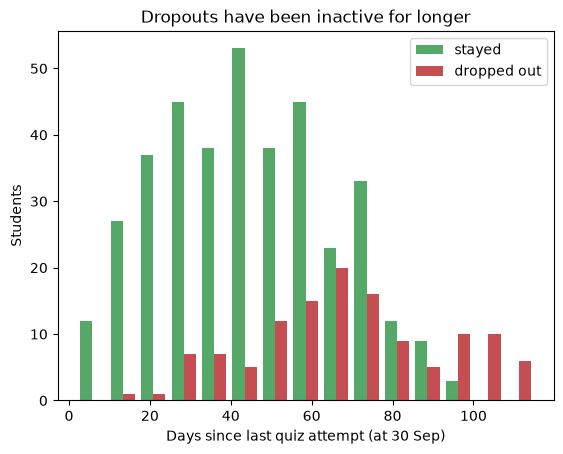

median days since last attempt: stayed 43.0 | dropped 68.0


In [5]:
#Finding 2, recency
stay = eda[eda.dropped == 0].days_since_last.dropna()
left = eda[eda.dropped == 1].days_since_last.dropna()
plt.hist([stay, left], bins=15, label=["stayed", "dropped out"], color=["#55a868", "#c44e52"])
plt.xlabel("Days since last quiz attempt (at 30 Sep)")
plt.ylabel("Students")
plt.title("Dropouts have been inactive for longer")
plt.legend()
plt.savefig(OUT + "f2_recency_vs_dropout.png", dpi=120, bbox_inches="tight")
plt.show()
print("median days since last attempt: stayed", stay.median(), "| dropped", left.median())

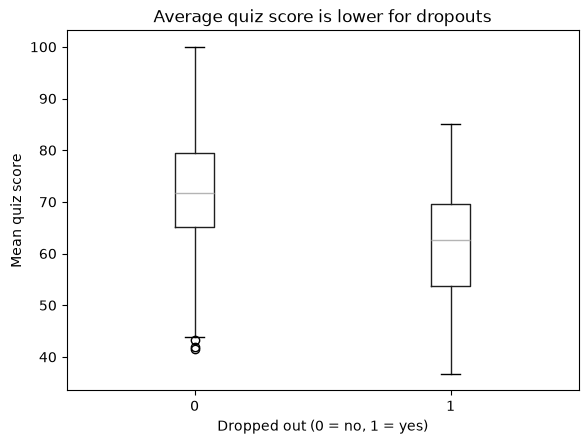

dropped
0    71.666667
1    62.666667
Name: mean_score, dtype: float64


In [6]:
#Finding 3, scores
ax = eda.boxplot(column="mean_score", by="dropped", grid=False)
plt.suptitle("")
ax.set_title("Average quiz score is lower for dropouts")
ax.set_xlabel("Dropped out (0 = no, 1 = yes)")
ax.set_ylabel("Mean quiz score")
plt.savefig(OUT + "f3_score_vs_dropout.png", dpi=120, bbox_inches="tight")
plt.show()
print(eda.groupby("dropped").mean_score.median())

                      mean  size
refund_requested                
no                0.049608   383
yes               0.905983   117


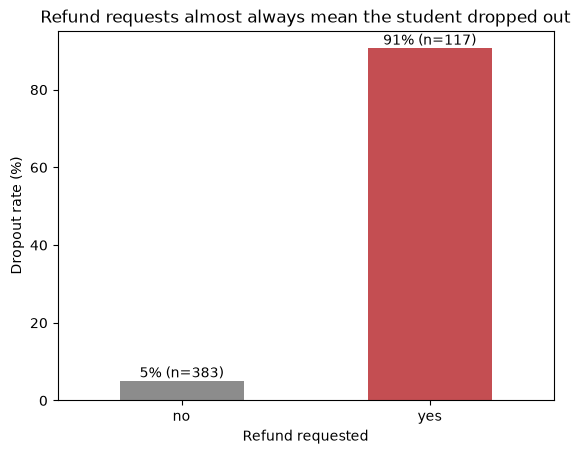

In [7]:
#Finding 4, refund requests
f4 = eda.groupby("refund_requested").dropped.agg(["mean", "size"])
print(f4)
ax = (f4["mean"] * 100).plot(kind="bar", color=["#8c8c8c", "#c44e52"], rot=0)
for i, (m, n) in enumerate(zip(f4["mean"], f4["size"])):
    ax.text(i, m * 100 + 1, f"{m*100:.0f}% (n={n})", ha="center")
ax.set_xlabel("Refund requested")
ax.set_ylabel("Dropout rate (%)")
ax.set_title("Refund requests almost always mean the student dropped out")
plt.savefig(OUT + "f4_refund_vs_dropout.png", dpi=120, bbox_inches="tight")
plt.show()

## Findings

Overall, 25% of students (125 of 500) dropped out, so the classes are imbalanced: a model that always says "stays" would be 75% accurate and catch nobody.

**Finding 1: fewer quiz attempts, more dropouts.**
- Evidence: dropout rate is 71% for students with 0-2 attempts (n=63), 39% for 3-4 (n=147), 12% for 5-6 (n=184) and 0% for 7+ (n=106). Chart: `outputs/f1_attempts_vs_dropout.png`.
- So what: engagement counts (attempts, lessons attempted) should be strong features.

**Finding 2: dropouts have been inactive for longer.**
- Evidence: the median time since the last attempt is 68 days for students who dropped out and 43 days for students who stayed. Chart: `outputs/f2_recency_vs_dropout.png`.
- So what: recency (days since last activity) is a useful feature.

**Finding 3: dropouts score lower, but the gap is smaller.**
- Evidence: median mean-score is about 63 for dropouts and about 72 for the others, and the two distributions overlap a lot. Chart: `outputs/f3_score_vs_dropout.png`.
- So what: scores help, but activity says more than marks. Struggling and dropping out are related, not identical.

**Finding 4: refund requests almost perfectly match dropout.**
- Evidence: 91% of students who requested a refund dropped out (n=117) versus 5% of those who did not (n=383). Chart: `outputs/f4_refund_vs_dropout.png`.
- So what: this looks too good to be a useful early signal. A refund request most likely comes at or after the moment a student leaves, so it is not known when we want to predict. Using it would inflate the model score without helping us catch students early. Decision for the model notebook: leave `refund_requested` out of the features (and show the score with and without it to prove the point).

**Caution on findings 1 and 2.** Attempts and recency are measured over the whole course. A student who dropped out in July naturally has fewer attempts and a longer silence by 30 September, so part of these signals is the outcome itself. That is a real limit of this dataset, because there is no dropout date. We keep the features, but treat the model score as optimistic. I will note this in the README.
